# 02 · Análisis exploratorio

Cada bloque parte de una pregunta y termina en una conclusión escrita. El foco son los
vídeos largos; los Shorts se usan solo como comparación. El horizonte principal es de
7 días y el de 28 días se mantiene como referencia.

1. ¿Cuánto del resultado a 7 días está decidido en los primeros días?
2. ¿Influyen el día y la hora de publicación?
3. ¿Qué anticipa mejor el resultado: el tamaño inicial o la velocidad de crecimiento?
4. ¿Qué vídeos hacen crecer el canal más allá de sus visualizaciones?
5. ¿Cómo cambia el origen de las visualizaciones según el rendimiento?
6. ¿Cómo es la retención de los mejores y los peores vídeos?
7. ¿A quién se parecen los largos de duración breve?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CSV_DIR = Path("../data/csv")
PROCESADO_DIR = Path("../data/processed")

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

maestra = pd.read_csv(
    PROCESADO_DIR / "videos_maestra.csv",
    parse_dates=["primer_dia", "fecha_publicacion_utc"],
)
maestra["published_at"] = pd.to_datetime(maestra["published_at"], utc=True)
panel = pd.read_csv(PROCESADO_DIR / "panel_diario.csv", parse_dates=["day"])

largos = maestra[maestra["formato"] == "long"].copy()
shorts = maestra[maestra["formato"] == "short"].copy()
print(f"Largos: {len(largos)} | Shorts: {len(shorts)}")

Largos: 260 | Shorts: 92


## 1. ¿Cuánto del resultado está decidido en los primeros días?

Para los vídeos con la ventana completa se calcula, día a día, qué fracción de sus minutos
y visualizaciones ya llevan acumulada respecto al total a 7 días, que es el horizonte
principal del modelo, y respecto al total a 28 días, que se mantiene como referencia
secundaria. Si a los 3 días ya se ha alcanzado buena parte del total a 7 días, tres días
de datos bastan para anticipar el resultado. El día 1 es el día de la publicación,
un día parcial.

Mediana del % del acumulado a 7 días alcanzado en cada día:
                         día 1  día 2  día 3  día 4  día 5  día 6  día 7
largos, minutos           47.5   76.3   87.1   93.0   96.4   98.7  100.0
largos, visualizaciones   45.5   74.8   85.7   92.4   95.9   98.4  100.0
Shorts, minutos           52.1   75.5   86.0   92.5   96.5   98.5  100.0
Shorts, visualizaciones   53.6   78.1   87.6   93.7   96.6   98.5  100.0

Mediana del % del acumulado a 28 días alcanzado en cada día:
                         día 1  día 2  día 3  día 7  día 14  día 28
largos, minutos           43.9   69.3   79.3   92.7    97.7   100.0
largos, visualizaciones   41.9   66.5   78.3   92.5    97.2   100.0
Shorts, minutos           45.1   66.0   77.3   91.4    96.4   100.0
Shorts, visualizaciones   47.8   69.2   78.2   92.1    96.0   100.0

Vídeos largos, minutos: dispersión del % del total a 7 días alcanzado:
         día 1  día 2  día 3
p10       17.9   46.7   64.3
p25       34.7   62.6   75.1
mediana   47.5

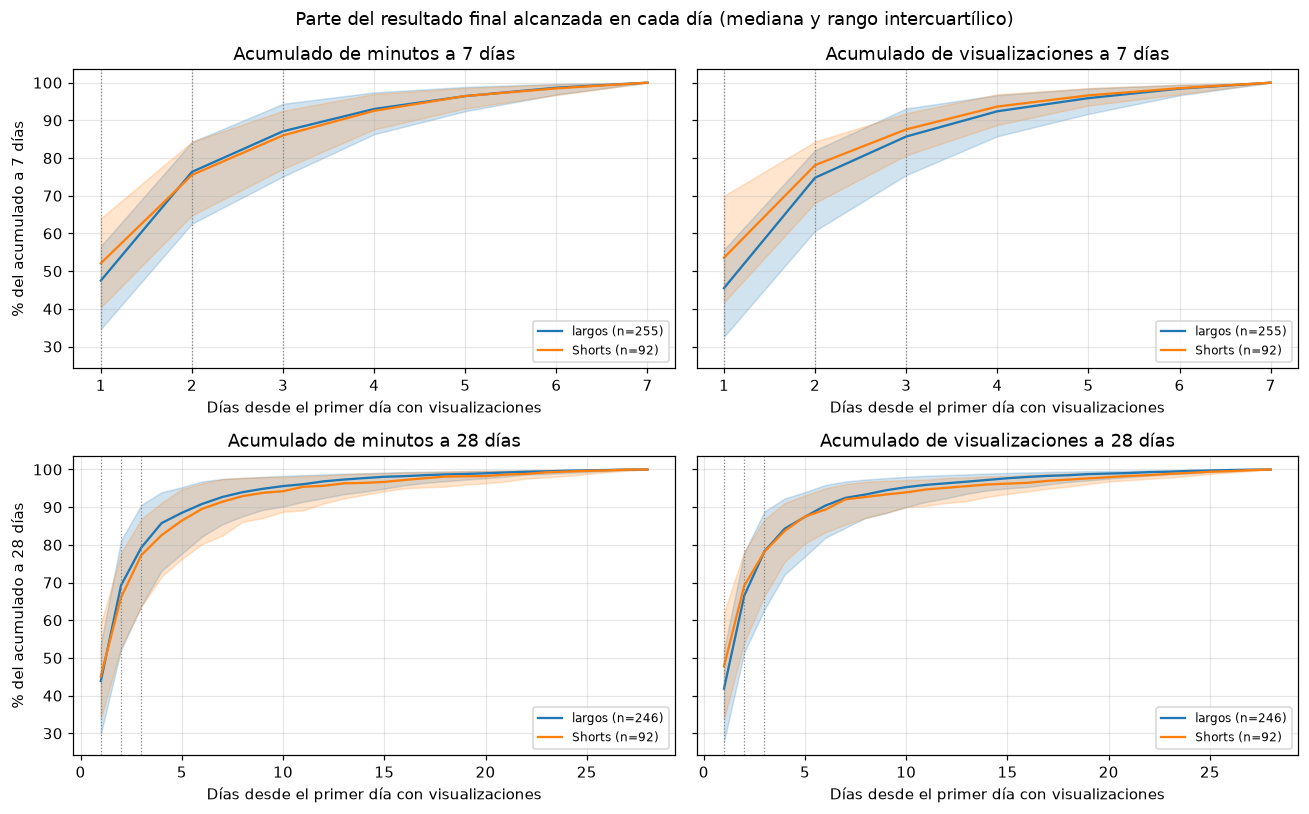

In [ ]:
HORIZONTES_CURVA = (7, 28)  # 7 días es el horizonte principal; 28 días, la referencia
MARCAS = {7: [1, 2, 3, 4, 5, 6, 7], 28: [1, 2, 3, 7, 14, 28]}
NOMBRES_FORMATO = {"long": "largos", "short": "Shorts"}
METRICAS_CURVA = (("estimatedMinutesWatched", "minutos"), ("views", "visualizaciones"))


def curva_acumulada(ids, metrica, horizonte):
    """Fracción del acumulado al final del horizonte que cada vídeo lleva en cada día."""
    base = panel[panel["video_id"].isin(ids) & (panel["dia_rel"] < horizonte)]
    por_dia = base.pivot_table(
        index="video_id", columns="dia_rel", values=metrica, aggfunc="sum", fill_value=0
    ).reindex(columns=range(horizonte), fill_value=0)
    acumulado = por_dia.cumsum(axis=1)
    total = acumulado[horizonte - 1]
    return acumulado.div(total.where(total > 0), axis=0)


resumen = {}
curvas = {}
for horizonte in HORIZONTES_CURVA:
    for formato, datos in (("long", largos), ("short", shorts)):
        ids = datos.loc[datos["dias_observados"] >= horizonte, "video_id"]
        for metrica, nombre in METRICAS_CURVA:
            curva = curva_acumulada(ids, metrica, horizonte)
            curvas[(horizonte, formato, nombre)] = curva
            resumen[(horizonte, formato, nombre)] = (
                curva[[m - 1 for m in MARCAS[horizonte]]].median().set_axis(MARCAS[horizonte])
            )

for horizonte in HORIZONTES_CURVA:
    filas = {
        f"{NOMBRES_FORMATO[formato]}, {nombre}": resumen[(horizonte, formato, nombre)]
        for formato in ("long", "short")
        for _, nombre in METRICAS_CURVA
    }
    tabla = pd.DataFrame(filas).T * 100
    tabla.columns = [f"día {m}" for m in MARCAS[horizonte]]
    print(f"Mediana del % del acumulado a {horizonte} días alcanzado en cada día:")
    print(tabla.round(1).to_string())
    print()

dispersion = pd.DataFrame(
    {
        f"día {m}": curvas[(7, "long", "minutos")][m - 1].quantile([0.1, 0.25, 0.5, 0.75, 0.9])
        for m in (1, 2, 3)
    }
) * 100
dispersion.index = ["p10", "p25", "mediana", "p75", "p90"]
print("Vídeos largos, minutos: dispersión del % del total a 7 días alcanzado:")
print(dispersion.round(1).to_string())

fig, ejes = plt.subplots(2, 2, figsize=(12, 7.5), sharey=True)
for fila, horizonte in enumerate(HORIZONTES_CURVA):
    dias = np.arange(1, horizonte + 1)
    for columna, (_, nombre) in enumerate(METRICAS_CURVA):
        eje = ejes[fila, columna]
        for formato, color in (("long", "tab:blue"), ("short", "tab:orange")):
            curva = curvas[(horizonte, formato, nombre)] * 100
            eje.plot(
                dias, curva.median().to_numpy(), color=color,
                label=f"{NOMBRES_FORMATO[formato]} (n={len(curva)})",
            )
            eje.fill_between(
                dias, curva.quantile(0.25).to_numpy(), curva.quantile(0.75).to_numpy(),
                color=color, alpha=0.2,
            )
        for marca in (1, 2, 3):
            eje.axvline(marca, color="gray", linestyle=":", linewidth=0.8)
        eje.set_title(f"Acumulado de {nombre} a {horizonte} días")
        eje.set_xlabel("Días desde la publicación (día 1 = día de publicación)")
        eje.legend(fontsize=8)
    ejes[fila, 0].set_ylabel(f"% del acumulado a {horizonte} días")
fig.suptitle("Parte del resultado final alcanzada en cada día (mediana y rango intercuartílico)")
fig.tight_layout()
plt.show()

**Conclusión.** A los 3 días un vídeo largo lleva en mediana el 87 % de los minutos que tendrá a los 7 días (el 85,7 % de las visualizaciones). A los 2 días lleva el 76 % y el primer día, el 47,5 %, que es un día natural y puede cubrir menos de 24 horas desde la publicación. Los Shorts arrancan algo más rápido (52-54 % el primer día), pero a los 3 días ambos formatos coinciden (86-88 %). Con 7 días ya se ha alcanzado el 93 % de los minutos a 28 días, así que el resultado a 28 días queda casi decidido a los 7 y la dificultad de predecir está en los primeros días.

La dispersión es amplia: en el 10 % de los largos con peor recorrido, más del 35 % de los minutos a 7 días llegan después del día 3, y el primer día reúne desde el 18 % (percentil 10) hasta el 67 % (percentil 90) del total. Son los vídeos que despegan tarde frente a los que lo concentran todo al principio. El modelo usará los minutos de cada uno de los primeros días y no solo su suma.

## 2. ¿Influyen el día y la hora de publicación?

Comparar los minutos a 7 días entre vídeos publicados en momentos distintos mezcla el
efecto de la hora con el tamaño del canal en cada época. Para separarlos, cada vídeo se
compara con la mediana de los 10 largos anteriores: un valor de 1 es un resultado
habitual en ese momento, y 2 es el doble de lo habitual.

Los datos no incluyen la actividad por horas de la audiencia, así que no se puede
contrastar si publicar antes del pico de audiencia funciona mejor. Solo se puede ver
cómo rinden los vídeos según su hora y día de publicación.

Largos con rendimiento relativo: 250
count     250.00
mean        8.06
std        72.41
min         0.05
25%         0.47
50%         1.02
75%         2.20
max      1130.59

Vídeos por hora de publicación (hora de Madrid):
hora_madrid
0      1
1      6
6      1
8      2
9      5
10    13
11    28
12    17
13    13
14    11
15     8
16    12
17    53
18    53
19    11
20     8
21     6
23     2

Por día de la semana:
            videos  rendimiento_p25  rendimiento_mediano  rendimiento_p75  minutos_7d_mediano
dia_nombre                                                                                   
lun             39             0.68                 1.33             2.66             24086.0
mar             49             0.44                 1.12             2.16             21088.0
mié             37             0.66                 1.55             2.95             13335.0
jue             35             0.42                 0.68             1.57             14253.0
vie             

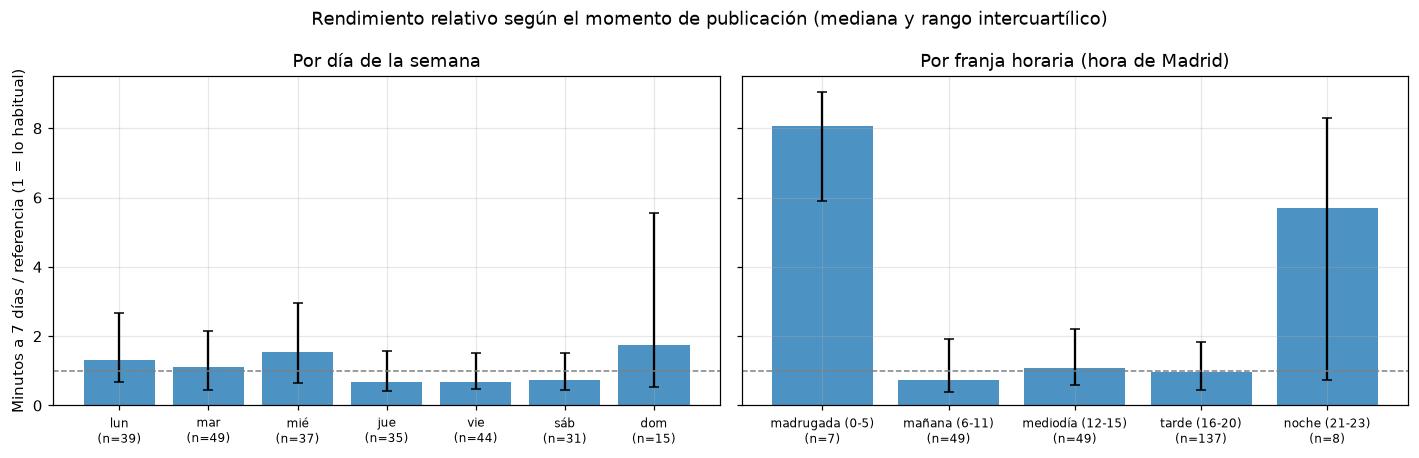

In [3]:
VENTANA_REFERENCIA = 10
NOMBRES_DIA = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
ETIQUETAS_FRANJA = [
    "madrugada (0-5)", "mañana (6-11)", "mediodía (12-15)", "tarde (16-20)", "noche (21-23)",
]

analisis = largos[largos["minutos_7d"].notna()].sort_values("primer_dia").copy()
analisis["referencia_7d"] = (
    analisis["minutos_7d"].shift(1).rolling(VENTANA_REFERENCIA, min_periods=5).median()
)
analisis["rendimiento_rel"] = analisis["minutos_7d"] / analisis["referencia_7d"].where(
    analisis["referencia_7d"] > 0
)
analisis = analisis.dropna(subset=["rendimiento_rel"]).copy()
print(f"Largos con rendimiento relativo: {len(analisis)}")
print(analisis["rendimiento_rel"].describe().round(2).to_string())

analisis["dia_nombre"] = pd.Categorical(
    analisis["dia_semana"].map(dict(enumerate(NOMBRES_DIA))),
    categories=NOMBRES_DIA,
    ordered=True,
)
analisis["franja"] = pd.cut(
    analisis["hora_madrid"], bins=[-1, 5, 11, 15, 20, 23], labels=ETIQUETAS_FRANJA
)

print("\nVídeos por hora de publicación (hora de Madrid):")
print(analisis["hora_madrid"].value_counts().sort_index().to_string())


def resumen_grupo(columna):
    """Resume el rendimiento relativo y los minutos a 7 días por grupo."""
    agrupado = analisis.groupby(columna, observed=True)
    return pd.DataFrame(
        {
            "videos": agrupado.size(),
            "rendimiento_p25": agrupado["rendimiento_rel"].quantile(0.25),
            "rendimiento_mediano": agrupado["rendimiento_rel"].median(),
            "rendimiento_p75": agrupado["rendimiento_rel"].quantile(0.75),
            "minutos_7d_mediano": agrupado["minutos_7d"].median(),
        }
    ).round(2)


print("\nPor día de la semana:")
print(resumen_grupo("dia_nombre").to_string())
print("\nPor franja horaria:")
print(resumen_grupo("franja").to_string())


def grafico_grupo(eje, columna, titulo):
    """Barras con la mediana del rendimiento relativo y su rango intercuartílico."""
    datos = analisis.groupby(columna, observed=True)["rendimiento_rel"]
    mediana = datos.median()
    p25, p75 = datos.quantile(0.25), datos.quantile(0.75)
    n = datos.size()
    posiciones = np.arange(len(mediana))
    eje.bar(
        posiciones, mediana.to_numpy(),
        yerr=[(mediana - p25).to_numpy(), (p75 - mediana).to_numpy()],
        capsize=3, color="tab:blue", alpha=0.8,
    )
    eje.axhline(1, color="gray", linestyle="--", linewidth=1)
    eje.set_xticks(posiciones)
    eje.set_xticklabels([f"{etiqueta}\n(n={n[etiqueta]})" for etiqueta in mediana.index], fontsize=8)
    eje.set_title(titulo)


fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
grafico_grupo(eje1, "dia_nombre", "Por día de la semana")
grafico_grupo(eje2, "franja", "Por franja horaria (hora de Madrid)")
eje1.set_ylabel("Minutos a 7 días / referencia (1 = lo habitual)")
fig.suptitle("Rendimiento relativo según el momento de publicación (mediana y rango intercuartílico)")
fig.tight_layout()
plt.show()

In [4]:
from scipy import stats

COLUMNAS_REVISION = ["title", "primer_dia", "hora_madrid", "minutos_7d", "referencia_7d", "rendimiento_rel"]
MIN_VIDEOS_GRUPO = 15

extremos = analisis[analisis["franja"].isin(["madrugada (0-5)", "noche (21-23)"])]
print("Vídeos publicados de madrugada o de noche:")
print(extremos[COLUMNAS_REVISION].round(1).to_string(index=False))

print("\nLos 10 mayores rendimientos relativos:")
print(analisis.nlargest(10, "rendimiento_rel")[COLUMNAS_REVISION].round(1).to_string(index=False))

# Referencia recalculada solo con vídeos desde 2025, para no mezclar épocas
reciente = (
    largos[(largos["primer_dia"] >= "2025-01-01") & largos["minutos_7d"].notna()]
    .sort_values("primer_dia")
    .copy()
)
reciente["referencia_7d"] = (
    reciente["minutos_7d"].shift(1).rolling(VENTANA_REFERENCIA, min_periods=VENTANA_REFERENCIA).median()
)
reciente["rendimiento_rel"] = reciente["minutos_7d"] / reciente["referencia_7d"].where(
    reciente["referencia_7d"] > 0
)
reciente = reciente.dropna(subset=["rendimiento_rel"]).copy()
reciente["dia_nombre"] = pd.Categorical(
    reciente["dia_semana"].map(dict(enumerate(NOMBRES_DIA))), categories=NOMBRES_DIA, ordered=True
)
reciente["franja"] = pd.cut(
    reciente["hora_madrid"], bins=[-1, 5, 11, 15, 20, 23], labels=ETIQUETAS_FRANJA
)
print(f"\nVídeos con referencia desde 2025: {len(reciente)}")
print(reciente["rendimiento_rel"].describe().round(2).to_string())

for columna in ("dia_nombre", "franja"):
    agrupado = reciente.groupby(columna, observed=True)["rendimiento_rel"]
    tabla = pd.DataFrame(
        {"videos": agrupado.size(), "p25": agrupado.quantile(0.25),
         "mediana": agrupado.median(), "p75": agrupado.quantile(0.75)}
    ).round(2)
    print(f"\n{columna}:")
    print(tabla.to_string())

    grupos = [g.to_numpy() for _, g in agrupado if len(g) >= MIN_VIDEOS_GRUPO]
    resultado = stats.kruskal(*grupos)
    print(f"Kruskal-Wallis con {len(grupos)} grupos de al menos {MIN_VIDEOS_GRUPO} vídeos: p = {resultado.pvalue:.3f}")

Vídeos publicados de madrugada o de noche:
                                                                                              title primer_dia  hora_madrid  minutos_7d  referencia_7d  rendimiento_rel
                       El Papá y el Betis. La profecía que lleva al Betis directo al título europeo 2025-02-27           21        69.0          504.0              0.1
                                       Antony tiene difícil seguir en el Betis, pero hay una opción 2025-03-03           21       517.0          111.0              4.7
¿Hasta cuándo se quedará Pellegrini? Datos y hechos que desmontan la teoría del fin de ciclo #Betis 2025-03-14           21     17949.0          211.5             84.9
                                                      Pellegrini y el arte de devolver la confianza 2025-04-24            1    538726.0          476.5           1130.6
                                            Cucho Hernández, ¿el gran 9 que tanto buscaba el Betis? 2025-04-27       

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_20708\2397099293.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(extremos[COLUMNAS_REVISION].round(1).to_string(index=False))
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_20708\2397099293.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(analisis.nlargest(10, "rendimiento_rel")[COLUMNAS_REVISION].round(1).to_string(index=False))


**Conclusión.** Con los datos disponibles no se puede afirmar que el día o la hora de publicación influyan en el rendimiento de un vídeo.

- **Día de la semana:** las medianas del rendimiento relativo van de 0,68 (jueves y viernes) a 1,75 (domingo), con rangos que se solapan casi por completo. El contraste de Kruskal-Wallis da p = 0,09, sin diferencias significativas al 5 %. Lunes, miércoles y domingo quedan algo por encima y jueves a sábado por debajo, un patrón débil que puede deberse al tipo de contenido de cada día.
- **Franja horaria:** entre mañana, mediodía y tarde, que son los grupos con 15 vídeos o más, las medianas son 0,79, 1,03 y 0,98 y no hay diferencias (p = 0,59). El canal publica casi siempre a la misma hora: 106 de 250 vídeos salen a las 17 o las 18 h, y apenas hay variación de la que aprender.
- **Madrugada y noche:** sus medianas altas (8,05 y 6,76) se apoyan en 7 vídeos por grupo y coinciden con momentos informativos concretos: la eliminatoria europea de la primavera de 2025 y el cierre del mercado de fichajes. La hora de esos vídeos es una consecuencia de la noticia, no una causa. En la noche hay además vídeos por debajo de lo habitual.
- **Limitación de la medida:** el rendimiento relativo compara cada vídeo con los 10 anteriores y se distorsiona cuando el canal crece de golpe (un vídeo de abril de 2025 llega a 1.131 veces su referencia). Por eso se usan medianas y cuartiles.

La hipótesis de publicar antes del pico de audiencia no se puede contrastar, porque los datos no incluyen la actividad por horas de la audiencia. Día y hora entrarán en el modelo como variables y se comprobará si pesan algo.

## 3. ¿Qué anticipa mejor el resultado: el tamaño inicial o la velocidad?

Se parte de los minutos de los 3 primeros días y se mira qué ocurre en los días 4 a 7
(el "futuro" del vídeo). Se comparan dos tipos de variables:

- Absolutas: minutos y visualizaciones acumulados en los primeros días.
- De velocidad: variación de los minutos de un día a otro, el peso del tercer día y los
  minutos por visualización.

Como el tamaño inicial ya explica buena parte del futuro, se calcula también qué parte no
explica (el residuo) y se comprueba si alguna variable de velocidad se relaciona con él.
Las correlaciones son de Spearman, que no se ve distorsionada por unos pocos vídeos con
cifras extremas.

Vídeos analizados: 250
Parte de la variación del futuro (log) explicada solo por el tamaño inicial: 0.56
Mediana del peso de los días 4-7 en los minutos a 7 días: 0.13

Correlación de Spearman:
                                          con el futuro (días 4-7)  con lo que el tamaño no explica
Minutos día 1 (absoluta)                                      0.64                             0.00
Minutos 3 días (absoluta)                                     0.72                             0.10
Visualizaciones 3 días (absoluta)                             0.69                             0.10
Suscriptores netos 3 días (absoluta)                          0.54                             0.05
Minutos día 2 / día 1 (velocidad)                             0.10                             0.19
Minutos día 3 / día 2 (velocidad)                             0.13                             0.32
Peso del día 3 en los 3 días (velocidad)                      0.19                             0.38
Minuto

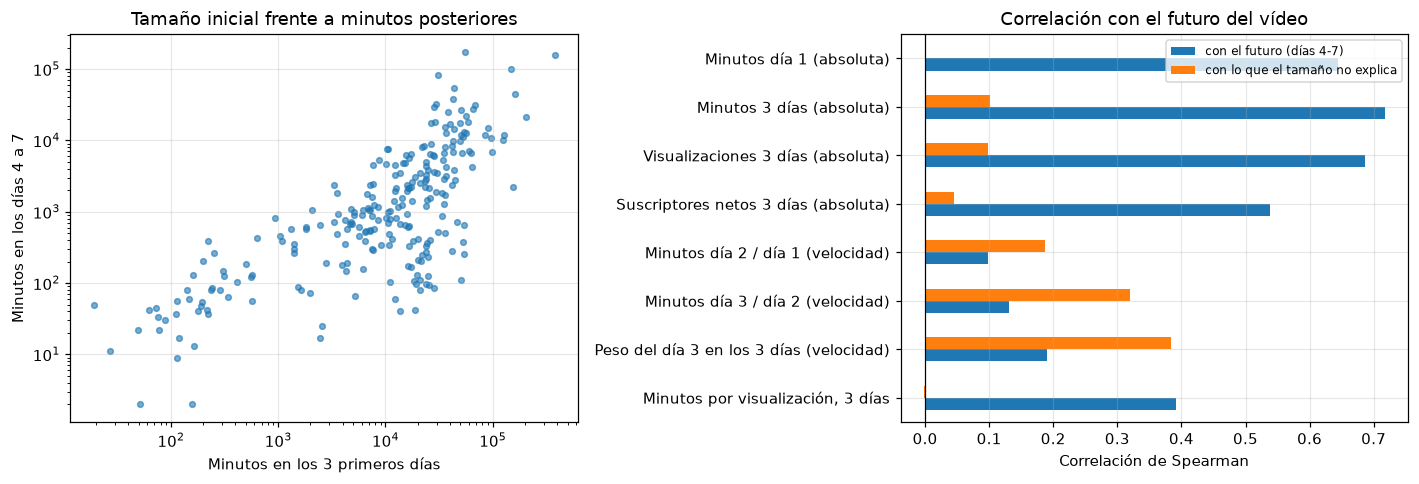

In [5]:
diarios = panel[panel["dia_rel"] < 3].pivot_table(
    index="video_id", columns="dia_rel", values="estimatedMinutesWatched", aggfunc="sum"
)
diarios.columns = ["min_d1", "min_d2", "min_d3"]

base = analisis.merge(diarios.reset_index(), on="video_id", how="left")
base["futuro_min"] = base["minutos_7d"] - base["minutos_3d"]
base["variacion_d2"] = base["min_d2"] / base["min_d1"].where(base["min_d1"] > 0)
base["variacion_d3"] = base["min_d3"] / base["min_d2"].where(base["min_d2"] > 0)
base["peso_dia3"] = base["min_d3"] / base["minutos_3d"].where(base["minutos_3d"] > 0)
base["min_por_vista_3d"] = base["minutos_3d"] / base["vistas_3d"].where(base["vistas_3d"] > 0)

VARIABLES = {
    "minutos_1d": "Minutos día 1 (absoluta)",
    "minutos_3d": "Minutos 3 días (absoluta)",
    "vistas_3d": "Visualizaciones 3 días (absoluta)",
    "subs_netos_3d": "Suscriptores netos 3 días (absoluta)",
    "variacion_d2": "Minutos día 2 / día 1 (velocidad)",
    "variacion_d3": "Minutos día 3 / día 2 (velocidad)",
    "peso_dia3": "Peso del día 3 en los 3 días (velocidad)",
    "min_por_vista_3d": "Minutos por visualización, 3 días",
}

# Parte del futuro que el tamaño inicial no explica (en escala logarítmica)
x = np.log1p(base["minutos_3d"])
y = np.log1p(base["futuro_min"])
pendiente, ordenada = np.polyfit(x, y, 1)
base["residuo"] = y - (pendiente * x + ordenada)
print(f"Vídeos analizados: {len(base)}")
print(f"Parte de la variación del futuro (log) explicada solo por el tamaño inicial: {np.corrcoef(x, y)[0, 1] ** 2:.2f}")
print(f"Mediana del peso de los días 4-7 en los minutos a 7 días: {(base['futuro_min'] / base['minutos_7d']).median():.2f}")

columnas = list(VARIABLES)
correlaciones = pd.DataFrame(
    {
        "con el futuro (días 4-7)": base[columnas].corrwith(base["futuro_min"], method="spearman"),
        "con lo que el tamaño no explica": base[columnas].corrwith(base["residuo"], method="spearman"),
    }
).rename(index=VARIABLES)
print("\nCorrelación de Spearman:")
print(correlaciones.round(2).to_string())

fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(13, 4.5))
eje1.scatter(base["minutos_3d"] + 1, base["futuro_min"] + 1, s=14, alpha=0.6)
eje1.set_xscale("log")
eje1.set_yscale("log")
eje1.set_xlabel("Minutos en los 3 primeros días")
eje1.set_ylabel("Minutos en los días 4 a 7")
eje1.set_title("Tamaño inicial frente a minutos posteriores")
correlaciones.iloc[::-1].plot.barh(ax=eje2)
eje2.axvline(0, color="black", linewidth=0.8)
eje2.set_title("Correlación con el futuro del vídeo")
eje2.set_xlabel("Correlación de Spearman")
eje2.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Conclusión.** Lo que mejor anticipa el resultado de los días 4 a 7 es el tamaño de los 3 primeros días. Los minutos acumulados en ese periodo tienen una correlación de Spearman de 0,72 con los minutos posteriores y, por sí solos, explican el 56 % de su variación en escala logarítmica. Las visualizaciones (0,69) y los suscriptores netos (0,54) de esos tres días se relacionan algo menos, y el primer día aislado (0,64) se acerca bastante al acumulado de tres días.

Lo que el tamaño no explica se asocia con la velocidad. Una vez descontado el tamaño inicial, las únicas variables con relación apreciable con el resto son el peso del tercer día en los tres primeros (0,38), el cociente de minutos entre el día 3 y el día 2 (0,32) y el del día 2 frente al día 1 (0,19): un vídeo cuyo tercer día todavía pesa mucho sigue creciendo más de lo esperado. Los minutos por visualización (0,00) y los suscriptores netos (0,05) no aportan nada una vez conocido el tamaño. Las variables absolutas salen casi nulas (hasta 0,10) por construcción, porque el residuo ya descuenta el tamaño.

El margen de predicción es pequeño en el vídeo mediano, donde los días 4 a 7 suponen solo el 13 % de los minutos a 7 días, pero llega a más del 35 % en los vídeos que despegan tarde (bloque 1). El gráfico muestra además que vídeos con un tamaño inicial parecido pueden terminar con resultados muy distintos, así que las previsiones deben darse como rango.

Limitaciones: el primer día es un día natural y cubre entre 0 y 24 horas posteriores a la publicación, según la hora a la que se subió el vídeo, por lo que las variables de velocidad que lo usan dependen en parte de esa hora. La muestra es de 250 vídeos largos y las correlaciones de velocidad son moderadas (hasta 0,38).

## 4. ¿Qué vídeos hacen crecer el canal más allá de sus visualizaciones?

Dos vídeos con las mismas visualizaciones pueden aportar un valor muy distinto. Para los
largos con 7 días completos y al menos 1.000 visualizaciones en ese periodo se calcula:

- Suscriptores netos (ganados menos perdidos) por cada 1.000 visualizaciones.
- Minutos vistos por visualización.

Después se compara el 20 % de vídeos con más suscriptores por 1.000 visualizaciones con el
resto, para ver qué rasgos tienen en común. El horizonte es el mismo que el del modelo.

Largos con 7 días y al menos 1000 visualizaciones: 190
       vistas_7d  minutos_7d  subs_por_1k  min_por_vista
count     190.00      190.00       190.00         190.00
mean     7770.17    38364.68         6.45           6.02
std     15320.17    53920.92         8.31           3.59
min      1035.00     1713.00        -0.76           1.03
25%      2374.25    12013.50         1.71           3.81
50%      3939.50    23056.50         4.22           5.23
75%      8369.75    46374.00         8.25           7.31
max    170903.00   538726.00        84.86          24.14

Correlación de Spearman:
                        vistas_7d  subs_por_1k  min_por_vista  duracion_min  porcentaje_visto_medio  hora_madrid  title_length
vistas_7d                    1.00         0.14          -0.15          0.01                   -0.01        -0.16          0.10
subs_por_1k                  0.14         1.00           0.36          0.21                    0.06         0.15          0.29
min_por_vista            

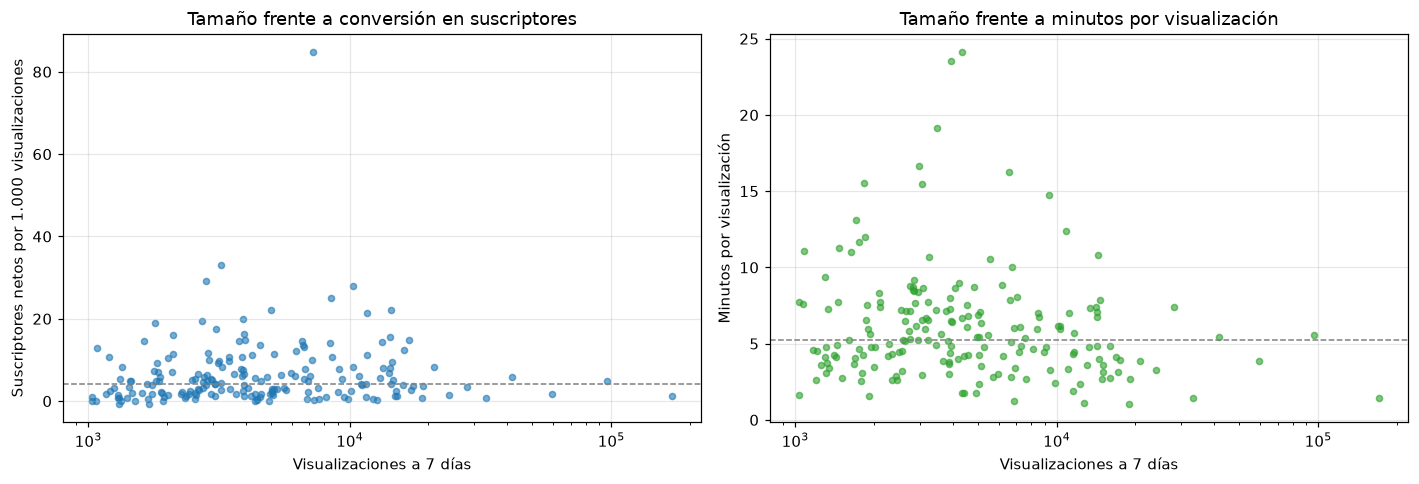

In [6]:
HORIZONTE_CALIDAD = 7
MIN_VISTAS = 1000

col_vistas = f"vistas_{HORIZONTE_CALIDAD}d"
col_minutos = f"minutos_{HORIZONTE_CALIDAD}d"
col_subs = f"subs_netos_{HORIZONTE_CALIDAD}d"

calidad = largos[largos[col_vistas] >= MIN_VISTAS].copy()
calidad["subs_por_1k"] = calidad[col_subs] / calidad[col_vistas] * 1000
calidad["min_por_vista"] = calidad[col_minutos] / calidad[col_vistas]
calidad["duracion_min"] = calidad["duration_seconds"] / 60
print(f"Largos con {HORIZONTE_CALIDAD} días y al menos {MIN_VISTAS} visualizaciones: {len(calidad)}")
print(calidad[[col_vistas, col_minutos, "subs_por_1k", "min_por_vista"]].describe().round(2).to_string())

columnas_corr = [
    col_vistas, "subs_por_1k", "min_por_vista", "duracion_min",
    "porcentaje_visto_medio", "hora_madrid", "title_length",
]
print("\nCorrelación de Spearman:")
print(calidad[columnas_corr].corr(method="spearman").round(2).to_string())

umbral = calidad["subs_por_1k"].quantile(0.8)
calidad["grupo"] = np.where(
    calidad["subs_por_1k"] >= umbral, "20 % con más suscriptores por 1.000", "resto"
)
comparacion = (
    calidad.groupby("grupo")[
        [col_vistas, col_minutos, "duracion_min", "min_por_vista",
         "porcentaje_visto_medio", "title_length", "hora_madrid"]
    ]
    .median()
    .round(2)
    .T
)
print("\nMedianas por grupo:")
print(comparacion.to_string())

columnas_tabla = ["title", col_vistas, "subs_por_1k", "min_por_vista", "duracion_min"]
ordenado = calidad.sort_values("subs_por_1k", ascending=False)
print("\n10 vídeos con más suscriptores netos por 1.000 visualizaciones:")
print(ordenado.head(10)[columnas_tabla].round(1).to_string(index=False))
print("\n10 con menos:")
print(ordenado.tail(10)[columnas_tabla].round(1).to_string(index=False))

fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(13, 4.5))
eje1.scatter(calidad[col_vistas], calidad["subs_por_1k"], s=16, alpha=0.6)
eje1.set_xscale("log")
eje1.axhline(calidad["subs_por_1k"].median(), color="gray", linestyle="--", linewidth=1)
eje1.set_xlabel(f"Visualizaciones a {HORIZONTE_CALIDAD} días")
eje1.set_ylabel("Suscriptores netos por 1.000 visualizaciones")
eje1.set_title("Tamaño frente a conversión en suscriptores")
eje2.scatter(calidad[col_vistas], calidad["min_por_vista"], s=16, alpha=0.6, color="tab:green")
eje2.set_xscale("log")
eje2.axhline(calidad["min_por_vista"].median(), color="gray", linestyle="--", linewidth=1)
eje2.set_xlabel(f"Visualizaciones a {HORIZONTE_CALIDAD} días")
eje2.set_ylabel("Minutos por visualización")
eje2.set_title("Tamaño frente a minutos por visualización")
fig.tight_layout()
plt.show()

**Conclusión.** Se analizan 190 largos con al menos 1.000 visualizaciones en 7 días. La mediana es de 4,2 suscriptores netos por cada 1.000 visualizaciones (rango intercuartílico de 1,7 a 8,25) y de 5,2 minutos por visualización. El análisis del fichaje procedente de Vélez Sarsfield es un caso aislado, con 84,9 suscriptores por 1.000 visualizaciones frente a los 33,0 del siguiente.

- **Tamaño y conversión casi no se relacionan** (correlación de 0,14 entre visualizaciones y suscriptores por 1.000). Los vídeos de más de 30.000 visualizaciones, pocos puntos en el gráfico, no alcanzan los valores más altos de conversión ni de minutos por visualización. Es un indicio débil, compatible con que la audiencia que llega con un vídeo muy distribuido sea menos fiel.
- **Los minutos por visualización dependen sobre todo de la duración** (correlación de 0,84), mientras que el porcentaje visto baja al alargarse el vídeo (-0,47). Por eso los minutos por visualización no sirven por sí solos para comparar la calidad de vídeos de distinta duración.
- **El 20 % que más suscriptores convierte** tiene un número de visualizaciones parecido al resto (mediana de 4.387 frente a 3.909), pero más minutos vistos (30.600 frente a 20.319), más minutos por visualización (6,4 frente a 4,8), algo más de duración (13,3 frente a 11,2 minutos) y títulos más largos (68,5 frente a 60 caracteres). La hora de publicación es la misma (17 h).
- **Temas** (lectura de títulos, sin clasificar): entre los 10 de mayor conversión hay seis sobre fichajes o mercado, tres análisis de rivales europeos y uno del derbi, contenidos dirigidos a quien ya sigue al club. Entre los 10 de menor conversión hay temas generales de fútbol o de negocio (calendario, mercado de camisetas, reparto de los fichajes, un Mundial), dos vídeos de la serie con invitados y tres sobre entrenadores o la renovación de Pellegrini.

El tema del vídeo parece influir en la captación de suscriptores y no se ha incorporado al modelo por falta de tiempo.

## 5. ¿Cómo cambia el origen de las visualizaciones según el rendimiento?

Se agrupan los largos en tres niveles según su rendimiento relativo a 7 días (el 25 %
superior, el 25 % inferior y el resto) y se compara el reparto de sus visualizaciones por
fuente de tráfico y entre audiencia suscrita y no suscrita.

Limitación: el reparto es el acumulado de toda la vida del vídeo. No se ve cómo evoluciona
con el tiempo, así que no se puede comprobar el recorrido "primero la audiencia habitual y
después usuarios nuevos". Solo se puede ver qué mezcla final tienen los vídeos que mejor y
peor funcionan.

nivel
alto (25 % superior)     63
medio                   124
bajo (25 % inferior)     63

% medio de visualizaciones por fuente de tráfico y nivel de rendimiento:
                      INICIO_Y_SUSCRIPCIONES  RELATED_VIDEO  YT_SEARCH  EXT_URL  NO_LINK_OTHER  YT_CHANNEL  OTRAS
nivel                                                                                                            
alto (25 % superior)                    60.0           20.0        5.1      4.2            2.6         3.5    4.6
medio                                   59.9           19.1        5.6      3.6            2.3         3.8    5.8
bajo (25 % inferior)                    57.8           14.7        4.8      4.8            2.3         7.6    8.0

% de visualizaciones de suscriptores, por nivel:
                      count  median  mean
nivel                                    
alto (25 % superior)     63    19.6  21.5
medio                   124    39.0  37.8
bajo (25 % inferior)     63    41.9  40.9

Corre

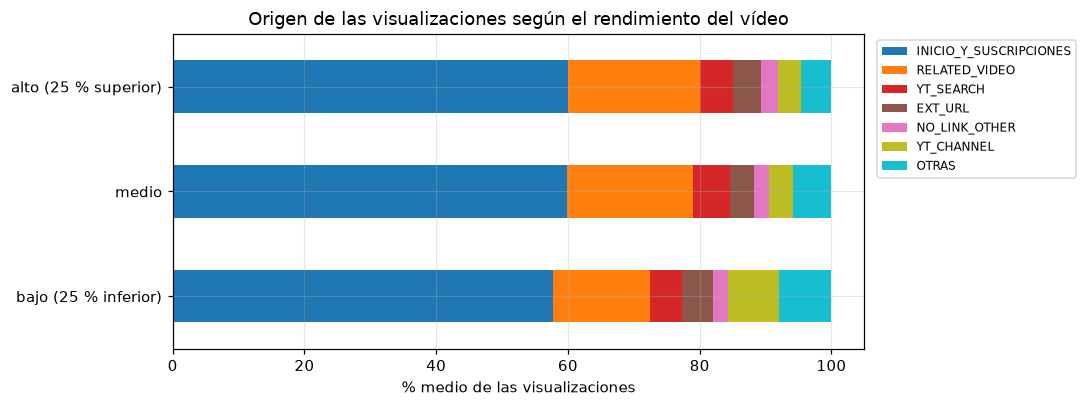

In [7]:
fuentes = pd.read_csv(CSV_DIR / "analytics_video_traffic_source.csv", encoding="utf-8-sig")
audiencia = pd.read_csv(CSV_DIR / "analytics_video_subscribed_status.csv", encoding="utf-8-sig")

q25, q75 = analisis["rendimiento_rel"].quantile([0.25, 0.75])
analisis["nivel"] = np.select(
    [analisis["rendimiento_rel"] >= q75, analisis["rendimiento_rel"] <= q25],
    ["alto (25 % superior)", "bajo (25 % inferior)"],
    default="medio",
)
ORDEN_NIVEL = ["alto (25 % superior)", "medio", "bajo (25 % inferior)"]
print(analisis["nivel"].value_counts().reindex(ORDEN_NIVEL).to_string())

# Reparto de visualizaciones por fuente: las 6 principales y el resto agrupado
vistas_fuente = (
    fuentes[fuentes["video_id"].isin(analisis["video_id"])]
    .pivot_table(
        index="video_id", columns="insightTrafficSourceType",
        values="views", aggfunc="sum", fill_value=0,
    )
)
principales = vistas_fuente.sum().sort_values(ascending=False).head(6).index
agrupado = vistas_fuente[principales].copy()
agrupado["OTRAS"] = vistas_fuente.drop(columns=principales).sum(axis=1)
cuota_fuente = (agrupado.div(agrupado.sum(axis=1).where(lambda s: s > 0), axis=0) * 100).rename(columns={"SUBSCRIBER": "INICIO_Y_SUSCRIPCIONES"})

por_nivel = cuota_fuente.join(analisis.set_index("video_id")["nivel"], how="inner")
reparto_fuentes = por_nivel.groupby("nivel").mean().reindex(ORDEN_NIVEL)
print("\n% medio de visualizaciones por fuente de tráfico y nivel de rendimiento:")
print(reparto_fuentes.round(1).to_string())

# Audiencia suscrita frente a no suscrita
vistas_audiencia = audiencia.pivot_table(
    index="video_id", columns="subscribedStatus", values="views", aggfunc="sum", fill_value=0
)
total_audiencia = vistas_audiencia[["SUBSCRIBED", "UNSUBSCRIBED"]].sum(axis=1)
cuota_suscritos = (
    vistas_audiencia["SUBSCRIBED"] / total_audiencia.where(total_audiencia > 0) * 100
).rename("cuota_suscritos")
con_audiencia = analisis.merge(cuota_suscritos.reset_index(), on="video_id", how="inner")
print("\n% de visualizaciones de suscriptores, por nivel:")
print(
    con_audiencia.groupby("nivel")["cuota_suscritos"]
    .agg(["count", "median", "mean"])
    .reindex(ORDEN_NIVEL)
    .round(1)
    .to_string()
)
print(
    "\nCorrelación de Spearman entre % de suscriptores y rendimiento relativo: "
    f"{con_audiencia['cuota_suscritos'].corr(con_audiencia['rendimiento_rel'], method='spearman'):.2f}"
)

fig, eje = plt.subplots(figsize=(10, 3.8))
reparto_fuentes.iloc[::-1].plot.barh(stacked=True, ax=eje, colormap="tab10")
eje.set_xlabel("% medio de las visualizaciones")
eje.set_ylabel("")
eje.set_title("Origen de las visualizaciones según el rendimiento del vídeo")
eje.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
plt.show()

In [8]:
con_audiencia["tramo_edad"] = pd.cut(
    con_audiencia["dias_observados"],
    bins=[0, 90, 365, np.inf],
    labels=["hasta 90 días", "91-365 días", "más de 365 días"],
)
print("Vídeos y mediana del % de visualizaciones de suscriptores, por antigüedad y nivel:")
print(
    con_audiencia.pivot_table(
        index="tramo_edad", columns="nivel", values="cuota_suscritos",
        aggfunc=["count", "median"], observed=True,
    ).round(1).to_string()
)

periodos = {
    "publicados hasta 2025": con_audiencia["primer_dia"] < "2026-01-01",
    "publicados en 2026": con_audiencia["primer_dia"] >= "2026-01-01",
}
for nombre, mascara in periodos.items():
    grupo = con_audiencia[mascara]
    corr = grupo["cuota_suscritos"].corr(grupo["rendimiento_rel"], method="spearman")
    print(f"{nombre}: {len(grupo)} vídeos, correlación de Spearman = {corr:.2f}")

corr_edad = con_audiencia["cuota_suscritos"].corr(con_audiencia["dias_observados"], method="spearman")
print(f"\nCorrelación entre % de suscriptores y antigüedad del vídeo: {corr_edad:.2f}")

Vídeos y mediana del % de visualizaciones de suscriptores, por antigüedad y nivel:
                               count                                          median                           
nivel           alto (25 % superior) bajo (25 % inferior) medio alto (25 % superior) bajo (25 % inferior) medio
tramo_edad                                                                                                     
hasta 90 días                      6                    9    19                 29.1                 50.3  37.2
91-365 días                       20                   24    54                 29.3                 53.2  50.6
más de 365 días                   37                   30    51                 12.0                 29.3  23.8
publicados hasta 2025: 158 vídeos, correlación de Spearman = -0.45
publicados en 2026: 92 vídeos, correlación de Spearman = -0.46

Correlación entre % de suscriptores y antigüedad del vídeo: -0.50


**Conclusión.** Se comparan 63 largos de rendimiento alto, 124 medios y 63 bajos, según su rendimiento relativo a 7 días.

- **Fuente principal:** la etiqueta `SUBSCRIBER` de la API agrupa los feeds de la página de inicio y las funciones de suscripción. Aporta en torno al 60 % de las visualizaciones en los tres niveles (60,0 %, 59,9 % y 57,8 %), de modo que el canal depende sobre todo de lo que YouTube le muestra en el inicio y en las suscripciones.
- **Vídeos sugeridos y páginas del canal:** los vídeos sugeridos aportan el 20,0 % en los de rendimiento alto, el 19,1 % en los medios y el 14,7 % en los bajos. Las visitas desde páginas del canal se duplican en los bajos (7,6 % frente al 3,5 % de los altos). La búsqueda es parecida en los tres niveles (entre el 4,8 % y el 5,6 %). Los vídeos que se quedan por debajo de lo esperado reciben menos recomendaciones desde otros vídeos y más visitas de quien ya entra al canal.
- **Audiencia suscrita:** es la señal más clara. En los vídeos de rendimiento alto la mediana de visualizaciones de espectadores suscritos es del 19,6 %, frente al 39,0 % de los medios y el 41,9 % de los bajos (correlación de Spearman de -0,42 con el rendimiento relativo). Los vídeos que superan lo habitual son los que llegan a espectadores que no son suscriptores.

**Comprobación de robustez.** La relación no se explica por la antigüedad ni por la época. Dentro de cada tramo de antigüedad, los vídeos de rendimiento alto tienen menos audiencia suscrita que los bajos: 29,1 % frente a 50,3 % en los de hasta 90 días, 29,3 % frente a 53,2 % en los de 91 a 365 días y 12,0 % frente a 29,3 % en los de más de un año. La correlación con el rendimiento es de -0,45 en los publicados hasta 2025 (158 vídeos) y de -0,46 en los de 2026 (92). La diferencia se da sobre todo entre los vídeos de rendimiento alto y el resto: entre 91 y 365 días, los medios y los bajos apenas se distinguen (50,6 % y 53,2 %).

La antigüedad es un factor aparte y de un peso parecido: cuanto más viejo es el vídeo, menor es su porcentaje de visualizaciones de suscriptores (correlación de -0,50), porque con el tiempo acumula visualizaciones de espectadores nuevos. En el tramo de hasta 90 días solo hay 6 vídeos de rendimiento alto, así que ahí la cifra es poco firme.

**Cómo interpretarlo.** El resultado es compatible con el recorrido que plantea el propietario (arrancar con la audiencia habitual y que YouTube pruebe después el vídeo con públicos más amplios), pero no lo demuestra. Por un lado, es en parte mecánico: la audiencia suscrita es un grupo limitado, y un vídeo solo supera lo habitual si llega a gente que no está suscrita. Por otro, los datos son acumulados de toda la vida del vídeo y no muestran cuándo llegó cada audiencia. Por eso este reparto se usa para describir y no como variable del modelo, ya que solo se conoce con el vídeo ya maduro.

## 6. ¿Cómo es la retención de los mejores y los peores vídeos?

La retención depende mucho de la duración, así que se muestran dos vistas:

- Retención típica por tramos de duración, para ver cómo cae la audiencia en cada tipo de vídeo.
- Retención relativa (la que calcula YouTube frente a vídeos de duración parecida) en los
  vídeos de rendimiento alto y bajo, que ya descuenta el efecto de la duración.

Largos por tramo de duración:
tramo_duracion
hasta 8 min       55
8-15 min         125
más de 15 min     80

Mediana de audienceWatchRatio en cada punto del vídeo, por duración:
marca            0.10   0.25   0.50   0.75   0.90
tramo_duracion                                   
hasta 8 min     0.605  0.469  0.387  0.333  0.279
8-15 min        0.600  0.544  0.476  0.415  0.359
más de 15 min   0.513  0.426  0.343  0.292  0.256

Mediana de relativeRetentionPerformance, vídeos de rendimiento alto y bajo:
marca                  0.10   0.25   0.50   0.75   0.90
nivel                                                  
alto (25 % superior)  0.545  0.540  0.459  0.450  0.385
bajo (25 % inferior)  0.444  0.498  0.483  0.429  0.317


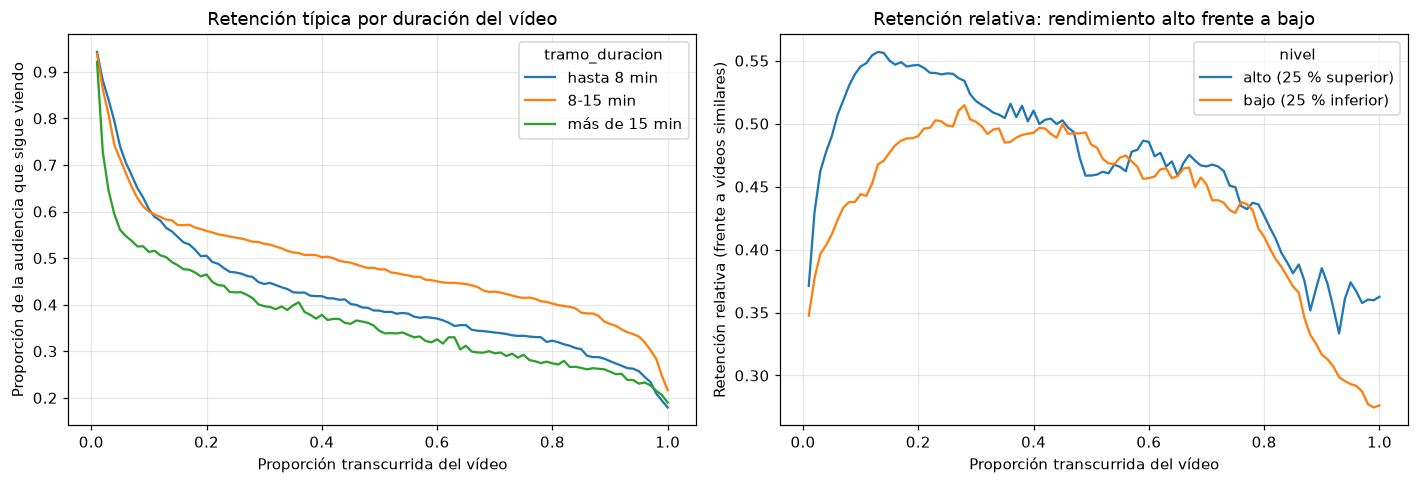

In [9]:
retencion = pd.read_csv(CSV_DIR / "analytics_video_retention.csv", encoding="utf-8-sig")

ret = retencion[retencion["video_id"].isin(largos["video_id"])].merge(
    largos[["video_id", "duration_seconds"]], on="video_id"
)
ret["tramo_duracion"] = pd.cut(
    ret["duration_seconds"],
    bins=[0, 480, 900, np.inf],
    labels=["hasta 8 min", "8-15 min", "más de 15 min"],
)
print("Largos por tramo de duración:")
print(ret.drop_duplicates("video_id")["tramo_duracion"].value_counts().sort_index().to_string())

curva_duracion = (
    ret.groupby(["tramo_duracion", "elapsedVideoTimeRatio"], observed=True)["audienceWatchRatio"]
    .median()
    .unstack(0)
)

ret_nivel = ret.merge(analisis[["video_id", "nivel"]], on="video_id", how="inner")
curva_nivel = (
    ret_nivel[ret_nivel["nivel"] != "medio"]
    .groupby(["nivel", "elapsedVideoTimeRatio"])["relativeRetentionPerformance"]
    .median()
    .unstack(0)
)

MARCAS_RET = [0.1, 0.25, 0.5, 0.75, 0.9]
ret["marca"] = ret["elapsedVideoTimeRatio"].round(2)
tabla_ret = ret[ret["marca"].isin(MARCAS_RET)].pivot_table(
    index="tramo_duracion", columns="marca", values="audienceWatchRatio",
    aggfunc="median", observed=True,
)
print("\nMediana de audienceWatchRatio en cada punto del vídeo, por duración:")
print(tabla_ret.round(3).to_string())

ret_nivel["marca"] = ret_nivel["elapsedVideoTimeRatio"].round(2)
tabla_rel = ret_nivel[
    ret_nivel["marca"].isin(MARCAS_RET) & (ret_nivel["nivel"] != "medio")
].pivot_table(
    index="nivel", columns="marca", values="relativeRetentionPerformance", aggfunc="median"
)
print("\nMediana de relativeRetentionPerformance, vídeos de rendimiento alto y bajo:")
print(tabla_rel.round(3).to_string())

fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(13, 4.5))
curva_duracion.plot(ax=eje1)
eje1.set_xlabel("Proporción transcurrida del vídeo")
eje1.set_ylabel("Proporción de la audiencia que sigue viendo")
eje1.set_title("Retención típica por duración del vídeo")
curva_nivel.plot(ax=eje2)
eje2.set_xlabel("Proporción transcurrida del vídeo")
eje2.set_ylabel("Retención relativa (frente a vídeos similares)")
eje2.set_title("Retención relativa: rendimiento alto frente a bajo")
fig.tight_layout()
plt.show()

**Conclusión.** La retención depende mucho de la duración, y el rendimiento alto se distingue sobre todo por el arranque.

- **Por duración:** a mitad del vídeo sigue viéndolo el 38,7 % de la audiencia en los de hasta 8 minutos (55 vídeos), el 47,6 % en los de 8 a 15 minutos (125) y el 34,3 % en los de más de 15 minutos (80). Los de 8 a 15 minutos retienen mejor que los más cortos desde el primer cuarto, y los de más de 15 minutos pierden más audiencia al principio: al 10 % del vídeo sigue el 51,3 %, frente a cerca del 60 % en los otros dos tramos. La duración se mezcla con el tipo de contenido, así que no se puede atribuir la diferencia solo a la duración.
- **Rendimiento alto frente a bajo (retención relativa):** la mediana de todos los puntos es de 0,49, coherente con que 0,5 sea el valor típico de un vídeo de su duración. Los vídeos de rendimiento alto superan a los bajos al inicio (0,55 frente a 0,44 al 10 % y 0,54 frente a 0,50 al 25 %), son parecidos en la parte central (0,46 frente a 0,48 a la mitad) y aguantan mejor el final (0,39 frente a 0,32 al 90 %).

La diferencia más clara está en los primeros minutos, y el arranque del vídeo es lo que más separa a unos de otros. No se puede decir qué causa qué: YouTube puede distribuir más los vídeos que retienen bien al principio, o esos vídeos pueden llegar a otra audiencia. Con 63 vídeos por grupo y sin medida de dispersión, las diferencias deben tomarse como orientativas.

## 7. ¿A quién se parecen los largos de duración breve?

Siete vídeos clasificados como largos caben en la duración de un Short. Se comparan con los
largos normales y con los Shorts en métricas de comportamiento de la audiencia para decidir
cómo tratarlos en el modelo.

In [10]:
comparativa = maestra.copy()
comparativa["grupo"] = np.select(
    [
        comparativa["formato"] == "short",
        (comparativa["formato"] == "long") & comparativa["largo_breve"],
    ],
    ["Short", "largo breve"],
    default="largo normal",
)
comparativa["min_por_vista"] = comparativa["minutos_total"] / comparativa["vistas_total"].where(
    comparativa["vistas_total"] > 0
)
comparativa["subs_netos_por_1k"] = (
    (comparativa["subs_ganados_total"] - comparativa["subs_perdidos_total"])
    / comparativa["vistas_total"].where(comparativa["vistas_total"] > 0)
    * 1000
)

retencion_50 = (
    retencion[retencion["elapsedVideoTimeRatio"].round(2) == 0.5][["video_id", "audienceWatchRatio"]]
    .rename(columns={"audienceWatchRatio": "retencion_50"})
)
comparativa = comparativa.merge(retencion_50, on="video_id", how="left")

tabla_grupos = comparativa.groupby("grupo").agg(
    videos=("video_id", "count"),
    duracion_mediana_s=("duration_seconds", "median"),
    porcentaje_visto=("porcentaje_visto_medio", "median"),
    min_por_vista=("min_por_vista", "median"),
    retencion_50=("retencion_50", "median"),
    subs_netos_por_1k=("subs_netos_por_1k", "median"),
).round(2)
print("Medianas por grupo:")
print(tabla_grupos.to_string())

breves = comparativa[comparativa["grupo"] == "largo breve"].sort_values("vistas_total", ascending=False)
breves = breves.assign(publicado=breves["published_at"].dt.date)
print("\nLos largos breves, uno a uno:")
print(
    breves[
        ["title", "publicado", "duration_seconds", "vistas_total",
         "porcentaje_visto_medio", "min_por_vista", "retencion_50"]
    ].round(2).to_string(index=False)
)

Medianas por grupo:
              videos  duracion_mediana_s  porcentaje_visto  min_por_vista  retencion_50  subs_netos_por_1k
grupo                                                                                                     
Short             92                55.0             70.28           0.38          0.68               1.01
largo breve        7               127.0             47.52           0.92          0.46               0.21
largo normal     253               677.0             42.74           4.73          0.42               4.29

Los largos breves, uno a uno:
                                                                                        title  publicado  duration_seconds  vistas_total  porcentaje_visto_medio  min_por_vista  retencion_50
                                 La transformación del Villamarín en 2 minutos (Toda la Obra) 2026-08-20               137       23815.0                   47.52           0.80          0.46
                             Pensa

**Conclusión.** Los 7 largos de duración breve (de 105 a 162 segundos) se comportan, en cuánto de cada vídeo ve la audiencia, más como largos que como Shorts: porcentaje visto medio del 47,5 % (largos normales, 42,7 %; Shorts, 70,3 %) y retención del 0,46 a mitad del vídeo (0,42 en largos y 0,68 en Shorts).

Sus minutos por visualización (0,92) quedan lejos de los largos normales (4,73), pero eso se debe a su duración y no a un comportamiento distinto. En suscriptores netos por 1.000 visualizaciones tienen el valor más bajo de los tres grupos: 0,21, frente a 1,01 de los Shorts y 4,29 de los largos.

Son pocos y muy desiguales: un solo vídeo, el de la transformación del Villamarín, reúne el 92 % de sus visualizaciones (23.815 de 25.931). Por eso se mantienen clasificados como largos, con la marca `largo_breve`, y en el modelo se comprobará que los resultados no cambian al quitarlos. Los datos no incluyen si el vídeo es vertical, que es lo que YouTube exige además de la duración para considerarlo un Short.